## Instructions for this notebook:

Prior to running this notebook, the following data must be downloaded and installed in the project folder under Data/Raw/manning/:

[CLRH Hydrofabric dataset](https://hydrology.uwaterloo.ca/CLRH/Hydrofabric.html) (download watershed of interest based on outlet point) 
- Extract zip file to: /Data/Raw/Manning/CLRH_RoutingProduct/

[WSC metadata](https://wateroffice.ec.gc.ca/station_metadata/station_characteristics_e.html) (of desired outlet point) 
- Save to: /Data/Raw/Manning/WSC_data

ACI Data (pre-clipped to watershed in ArcGIS Pro)
- Extract zip file to: /Data/Raw/Manning/ACI_2023

In [1]:
import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString, Polygon, MultiPoint
import sys
import math
import numpy

sys.path.append("..")
from src.py.proj_conf import *

## Read in Basinmaker Routing Product and WSC Outlet Point

In [93]:
# Read BasinMaker shapefile
basins_gdf = gpd.read_file(DATA_RAW + "CLRH_RoutingProduct/05OE006/finalcat_info_v1-0_Project.shp")

# Read WSC outlet point metadata
wsc_dp = pd.read_csv(DATA_RAW + "WSC_data/station_metadata_historical.csv")

In [15]:
# Convert csv to geodataframe
wsc_dp_gdf = gpd.GeoDataFrame(
    wsc_dp,
    geometry = gpd.points_from_xy(
        x = wsc_dp.Longitude,
        y = wsc_dp.Latitude,
        crs = 'EPSG:4326', # or: crs = pyproj.CRS.from_user_input(4326)
    )
)

# Identify initial subbasin containing WSC outlet point
point = wsc_dp_gdf.geometry
for i, row in basins_gdf.iterrows():
    if row.geometry.contains(point).any():
        dp = row['SubId']
        break
    else:
        dp = None


## Old code. Deprecated.
# basins_gdf['contains_point'] = gdf.geometry.contains(point, align = False)
# # wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')
# wsc_basins = basins_gdf[basins_gdf['contains_point'] == True]
# dp = wsc_basins['SubId'].values
# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

310019529


## Select Manning Cannal Subbasins

In [4]:
basins_gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
basins_gdf_project = basins_gdf.to_crs(4326)

[310019529]
[310019529, 310015222]
[310019529, 310015222, 310015221, 310015223, 310015224, 310015229, 310015230, 310015239, 310015237, 310015233, 310015234, 310015238, 310015240, 310015249, 310015252, 310015265, 310015266, 310015271, 310015272, 310015283, 310015284, 310015289, 310015290, 310015295, 310015296, 310015301, 310015302, 310015327, 310015328, 310015329, 310015330, 310015351, 310015352, 310013151, 310013152, 310013155, 310013156, 310013179, 310013180, 310013183, 310013184, 310020417, 310020436, 310020452, 310020479, 310020486, 310020487, 310020489, 310020491, 310020492, 310020502, 310020508, 310020535, 310020542, 310020551, 310020566, 310020587, 310020603, 310020623, 310020644, 310020668]


(np.float64(-96.9552346394395),
 np.float64(-96.47692779424655),
 np.float64(49.2988304774529),
 np.float64(49.663864777952014))

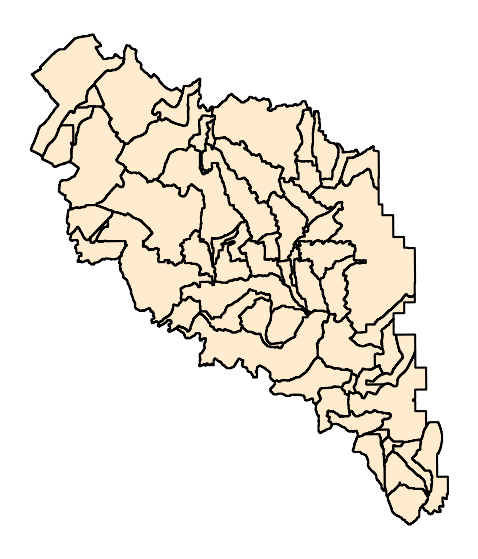

In [6]:

# Identify initial subbasin containing WSC outlet point
point = Point(wsc_dp.Longitude, wsc_dp.Latitude)
#point = wsc_dp_gdf.geometry
basins_gdf_project['contains_point'] = basins_gdf_project.geometry.contains(point, align = False)

# wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')

wsc_basins = basins_gdf_project[basins_gdf_project['contains_point'] == True]
dp = wsc_basins['SubId'].values

# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

# Create list containing inital Manning Canal subbasins and its upstream subbasin
for i, row in basins_gdf_project.iterrows():
    if row['DowSubId'] == dp:
        sub_select = [row['DowSubId'], row['SubId']]

print(sub_select)

# Add subbasins to Manning Canal list if they are connected to previously added subbasins (via DowSubId field)
n = 0
while n == 0:
    for i, row in basins_gdf_project.iterrows():
        if row['DowSubId'] in sub_select and row['SubId'] not in sub_select:
            sub_select.append(row['SubId'])
            break
    else:
        n = 1
print(sub_select)

# Create geodataframe containing Manning Canal subbasins
mc_gdf = basins_gdf_project[basins_gdf_project['SubId'].isin(sub_select)]

# Plot Manning Canal subbasins
f, ax = plt.subplots(1,1,figsize=(7,7))
mc_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')

## Select PHyDAP Hydrobasins

In [92]:
# Read PHyDAP Hydrobasin shapefile
phydap_basins_gdf = gpd.read_file(DATA_RAW + "PHyDAP_Hydrobasins/prairie_hydrosheds_true_WGS84.shp")

In [95]:
# Identify initial subbasin containing WSC outlet point
point = Point(wsc_dp.Longitude, wsc_dp.Latitude)
#point = wsc_dp_gdf.geometry
phydap_basins_gdf['contains_point'] = phydap_basins_gdf.geometry.contains(point, align = False)

# wsc_basins = basins_gdf.sjoin(point, how = 'inner', predicate = 'contains')

wsc_basins = phydap_basins_gdf[phydap_basins_gdf['contains_point'] == True]
dp = wsc_basins['HYBAS_ID'].values

# for i, row in basins_gdf.iterrows():
#     if row['contains_point'] == True:
#            dp = row['SubId']
           
print(dp)

# Create list containing inital Manning Canal subbasins and its upstream subbasin
for i, row in phydap_basins_gdf.iterrows():
    if row['NEXT_DOWN'] == dp:
        sub_select = [row['NEXT_DOWN'], row['HYBAS_ID']]

print(sub_select)

# Add subbasins to Manning Canal list if they are connected to previously added subbasins (via DowSubId field)
n = 0
while n == 0:
    for i, row in phydap_basins_gdf.iterrows():
        if row['NEXT_DOWN'] in sub_select and row['HYBAS_ID'] not in sub_select:
            sub_select.append(row['HYBAS_ID'])
            break
    else:
        n = 1
print(sub_select)

# Create geodataframe containing Manning Canal subbasins
mc_phydap_gdf = phydap_basins_gdf[phydap_basins_gdf['HYBAS_ID'].isin(sub_select)]

# Plot Manning Canal subbasins
f, ax = plt.subplots(1,1,figsize=(7,7))
mc_phydap_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')

[7120288510]


KeyError: 'NEXT_DOWN'

## Calculate Routing Parameters

In [19]:
# Calculate time of concentration and time to peak
cn = 63
mc_gdf['BasinsArea_acres'] = mc_gdf['BasArea'] * 0.00024710538
mc_gdf['FlowLength_ft'] = 209 * (mc_gdf['BasinsArea_acres']**0.6)
mc_gdf['BasSlope_prcnt'] = numpy.tan(numpy.radians(mc_gdf['BasSlope'])) * 100
mc_gdf['max_retention'] = (1000 / cn) - 10
mc_gdf['time_of_conc'] = ((mc_gdf['FlowLength_ft']**0.8) * ((mc_gdf['max_retention'] + 1)**0.7)) / (1140 * (mc_gdf['BasSlope_prcnt']**0.5))
mc_gdf['time_to_peak'] = mc_gdf['time_of_conc'] * 0.6

mc_gdf.head()

,SubId,DowSubId,RivSlope,RivLength,BasSlope,BasAspect,BasArea,BkfWidth,BkfDepth,Lake_Cat,...,SSDA_NM,SDA_NM,geometry,contains_point,BasinsArea_acres,FlowLength_ft,BasSlope_prcnt,max_retention,time_of_conc,time_to_peak
0,310013151,310015352,0.001359,1472.132034,0.139288,101.631184,1020600.0,3.598586,0.178092,0.0,...,Nelson,05OS,"POLYGON ((-96.6018 49.40315, -96.60345 49.4031...",False,252.195751,5770.174473,0.243105,5.873016,7.000884,4.200530
1,310013152,310015352,0.000777,3362.132034,0.341033,113.693816,5556600.0,1.557162,0.107737,0.0,...,Nelson,05OS,"POLYGON ((-96.63637 49.39646, -96.63596 49.396...",False,1373.065755,15950.014693,0.595222,5.873016,10.091778,6.055067
2,310013155,310013151,0.000768,1301.543289,0.094106,59.975058,3028500.0,1.322273,0.100000,0.0,...,Nelson,05OS,"MULTIPOLYGON (((-96.57026 49.42224, -96.56985 ...",False,748.358643,11081.847094,0.164246,5.873016,14.356245,8.613747
3,310013156,310013151,0.000496,6743.452378,0.136037,93.606178,18478800.0,3.324347,0.169820,0.0,...,Nelson,05OS,"POLYGON ((-96.54526 49.37105, -96.54527 49.371...",False,4566.210896,32800.454815,0.237430,5.873016,28.446865,17.068119
4,310013179,310013156,0.000032,796.690476,0.085525,40.444107,742500.0,1.155956,0.100000,0.0,...,Nelson,05OS,"POLYGON ((-96.56666 49.36742, -96.56708 49.367...",False,183.475745,4767.530515,0.149269,5.873016,7.669169,4.601501


## Write MC subbasins geodataframe to shapefile

In [21]:
if not os.path.exists(DATA_PROCESSED + "Subbasins"):
    os.makedirs(DATA_PROCESSED + "Subbasins")

mc_gdf.to_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")

C:\Users\tsaleh\AppData\Local\Temp\ipykernel_14072\1911698736.py:4: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  mc_gdf.to_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")
c:\Users\tsaleh\.conda\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'contains_point' to 'contains_p'
  ogr_write(
c:\Users\tsaleh\.conda\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'BasinsArea_acres' to 'BasinsArea'
  ogr_write(
c:\Users\tsaleh\.conda\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'FlowLength_ft' to 'FlowLength'
  ogr_write(
c:\Users\tsaleh\.conda\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'BasSlope_prcnt' to 'BasSlope_p'
  ogr_write(
c:\Users\tsaleh\.conda\envs\pwa_dev\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarni

## Process ACI Raster

NOTE: ACI raster was pre-clipped to manning canal watershed in ArcGIS Pro

In [30]:
import rasterio
import rasterio.mask
import fiona

Warning: changing project projection for simplicity (no pre-built functions exist for easy reprojection of GeoTIFF files)

In [28]:
# Project mc subbasins to align with aci raster
with rasterio.open(DATA_RAW + "ACI_2023/aci_2023_clip_mc_clrh.tif") as aci_src:
    print(aci_src.crs)

mc_subbasins = gpd.read_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")
mc_subbasins_project = mc_subbasins.to_crs(3857)

EPSG:3857


In [75]:
# Calculate percent of each land cover type per subbasin

# Open the raster file
with rasterio.open(DATA_RAW + "ACI_2023/aci_2023_clip_mc_clrh.tif") as src:
    results = []

    # Iterate over each subbasins polygon
    for index, row in mc_subbasins_project.iterrows():
        polygon = [row["geometry"]]
        
        # Mask (crop) the raster to the polygon
        out_image, out_transform = rasterio.mask.mask(src, polygon, crop=True)

        # Remove NoData values (0 & 255)
        valid_data = out_image[numpy.isin(out_image, [0, 45, 46, 48, 55, 57, 58, 59, 60, 61, 62, 63, 64, 255], invert=True)].flatten()

        if len(valid_data) == 0:
            continue  # Skip empty polygons

        # Find unique classes and their counts
        unique_classes, counts = numpy.unique(valid_data, return_counts=True)

        # Compute total valid pixels
        total_pixels = counts.sum()

        # Compute percentages
        class_percentages = {cls: (count / total_pixels) * 100 for cls, count in zip(unique_classes, counts)}

        # Store results
        results.append({"Polygon_ID": index, "Class_Percentages": class_percentages})

# Print results
#for res in results:
    #print(f"Polygon {res['Polygon_ID']}:")
    
    # Convert NumPy types to Python native types
    #class_percentages = {int(cls): float(percent) for cls, percent in res["Class_Percentages"].items()}
    
    #for cls, percent in class_percentages.items():
        #print(f"  - Class {cls}: {percent:.2f}%")

    #for cls, percent in class_percentages.items():
        #class_name = CLASS_NAMES.get(cls, f"Class {cls}")  # Use name or default to "Class X"
        #print(f"  - {class_name}: {percent:.2f}%")
    
    #print()

# Output results as csv
data = []
for res in results:
    subbasin_id = res["Polygon_ID"]  # Treat as column names

    # Convert NumPy types to Python native types
    class_percentages = {int(cls): float(percent) for cls, percent in res["Class_Percentages"].items()}
    
    for cls, percent in class_percentages.items():
        crop_type = CLASS_NAMES.get(cls, f"Class {cls}")  # Use name or default to "Class X"
        data.append([crop_type, subbasin_id, percent])

# Convert to DataFrame
df = pd.DataFrame(data, columns=["Crop_Type", "Subbasin_ID", "Percentage"])

# Pivot the table to have Crop_Type as rows and Subbasin_ID as columns
df_pivot = df.pivot(index="Crop_Type", columns="Subbasin_ID", values="Percentage").fillna(0)  # Replace NaN with 0

# Save the pivoted DataFrame to CSV
df_pivot.to_csv(DATA_PROCESSED + "ACI/percent_crop_type_per_subbasin_MC.csv")

print("CSV saved successfully")


Polygon 0:
  - Class 24: 0.45%
  - Class 32: 0.34%
  - Class 45: 1.79%
  - Class 55: 0.34%
  - Class 57: 0.30%
  - Class 58: 8.19%
  - Class 59: 0.11%
  - Class 60: 85.70%
  - Class 63: 1.42%
  - Class 64: 1.38%

Polygon 1:
  - Class 19: 0.37%
  - Class 45: 5.86%
  - Class 46: 0.24%
  - Class 55: 0.56%
  - Class 57: 0.06%
  - Class 58: 7.55%
  - Class 60: 82.42%
  - Class 63: 2.41%
  - Class 64: 0.52%

Polygon 2:
  - Class 24: 1.19%
  - Class 45: 2.74%
  - Class 55: 2.00%
  - Class 57: 2.26%
  - Class 58: 6.55%
  - Class 59: 2.27%
  - Class 60: 77.73%
  - Class 61: 0.36%
  - Class 63: 3.19%
  - Class 64: 1.70%

Polygon 3:
  - Class 2: 0.17%
  - Class 16: 0.00%
  - Class 19: 4.82%
  - Class 24: 2.25%
  - Class 32: 2.39%
  - Class 45: 8.90%
  - Class 46: 3.67%
  - Class 55: 2.66%
  - Class 57: 0.17%
  - Class 58: 5.39%
  - Class 59: 1.87%
  - Class 60: 65.29%
  - Class 61: 0.00%
  - Class 63: 1.46%
  - Class 64: 0.95%

Polygon 4:
  - Class 45: 2.43%
  - Class 55: 8.05%
  - Class 58: 44.2

## Delineate Upper Manning with Whitebox

In [35]:
import sys
# !{sys.executable} -m pip install whitebox
import whitebox
wbt = whitebox.WhiteboxTools()

import shapely
import rasterio
import rasterio.plot
from osgeo import gdal

ModuleNotFoundError: No module named 'osgeo'

In [ ]:
# Resample dem

#wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")

#dem = "sr_dem_cgvd28_Resamp_1.tif"
#dem_90m = gdal.Warp('sr_dem_cgvd28_90m.tif', dem, dstSRS= 'EPSG:26914', xRes = 90, yRes =-90, resampleAlg='cubic')

In [525]:
print(os.getcwd() + wbt.get_working_dir())

c:\Users\tsaleh\Documents\GIS-Projects\PWA\_notebooks


In [13]:
# Set working directory
wbt.set_working_dir(os.getcwd() + '/' + DATA_RAW + "DEMs")

# Fill depressions in DEM
wbt.fill_depressions(
    dem = "sr_dem_cgvd28_Resamp_1.tif",
    output = "mc_filldep.tif",
    fix_flats=True,
    flat_increment=None,
    max_depth=None
)

.\whitebox_tools.exe --run="FillDepressions" --wd="c:\Users\tsaleh\Documents\GIS-Projects\PWA\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_filldep.tif' --fix_flats -v --compress_rasters=False

******************************
* Welcome to FillDepressions *
* Powered by WhiteboxTools   *
* www.whiteboxgeo.com        *
******************************
Reading data...
Finding pit cells: 5%
Finding pit cells: 10%
Finding pit cells: 15%
Finding pit cells: 20%
Finding pit cells: 25%
Finding pit cells: 30%
Finding pit cells: 35%
Finding pit cells: 40%
Finding pit cells: 45%
Finding pit cells: 50%
Finding pit cells: 55%
Finding pit cells: 60%
Finding pit cells: 65%
Finding pit cells: 70%
Finding pit cells: 75%
Finding pit cells: 80%
Finding pit cells: 85%
Finding pit cells: 90%
Finding pit cells: 95%
Finding pit cells: 100%
Filling depressions: 0%
Filling depressions: 1%
Filling depressions: 2%
Filling depressions: 3%
Filling depressions: 4%
Filling depressions: 5%
Fillin

0

In [14]:
# Set working directory
wbt.set_working_dir("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs")


# Breach depressions in DEM
wbt.breach_depressions_least_cost(
    dem = "sr_dem_cgvd28_Resamp_1.tif",
    output = "mc_breachdep.tif", 
    dist = 1000, 
    max_cost=None, 
    min_dist=True, 
    flat_increment=None, 
    fill=True
)

# Create flow accumulation raster
wbt.d8_flow_accumulation(
    i = "mc_breachdep.tif", 
    output = "mc_flowaccgrid.tif", 
    out_type="cells", 
    log=False, 
    clip=False, 
    pntr=False, 
    esri_pntr=False
)

# Extract streams from flow accumulation raster
wbt.extract_streams(
    flow_accum='mc_flowaccgrid.tif', 
    output='mc_streams_90000.tif', 
    threshold=90000.000000, 
    zero_background=True, 
)

# Create flow pointer (flow direction) raster
wbt.d8_pointer(
    dem = "mc_breachdep.tif",
    output = "mc_flowpointergrid.tif",
    esri_pntr=False
)

# Snap pour points to stream network
wbt.jenson_snap_pour_points(
    pour_pts = "mc_pp_extract.shp", 
    streams = "mc_streams_90000.tif", 
    output = "mc_pp_snap_2000m.shp", 
    snap_dist = 2000.0
)

# Derive watershed areas
wbt.watershed(
    d8_pntr = 'mc_flowpointergrid.tif', 
    pour_pts = 'mc_pp_snap_2000m.shp', 
    output = 'mc_watershed_90000.tif', 
    esri_pntr=False
)

.\whitebox_tools.exe --run="BreachDepressionsLeastCost" --wd="c:\Users\tsaleh\Documents\GIS-Projects\PWA\Data\Raw\manning\DEMs" --dem='sr_dem_cgvd28_Resamp_1.tif' --output='mc_breachdep.tif' --dist='1000' --min_dist --fill -v --compress_rasters=False

*****************************************
* Welcome to BreachDepressionsLeastCost *
* Powered by WhiteboxTools              *
* www.whiteboxgeo.com                   *
*****************************************
Reading data...
Finding pits: 0%
Finding pits: 1%
Finding pits: 2%
Finding pits: 3%
Finding pits: 4%
Finding pits: 5%
Finding pits: 6%
Finding pits: 7%
Finding pits: 8%
Finding pits: 9%
Finding pits: 10%
Finding pits: 11%
Finding pits: 12%
Finding pits: 13%
Finding pits: 14%
Finding pits: 15%
Finding pits: 16%
Finding pits: 17%
Finding pits: 18%
Finding pits: 19%
Finding pits: 20%
Finding pits: 21%
Finding pits: 22%
Finding pits: 23%
Finding pits: 24%
Finding pits: 25%
Finding pits: 26%
Finding pits: 27%
Finding pits: 28%
Finding pi

0

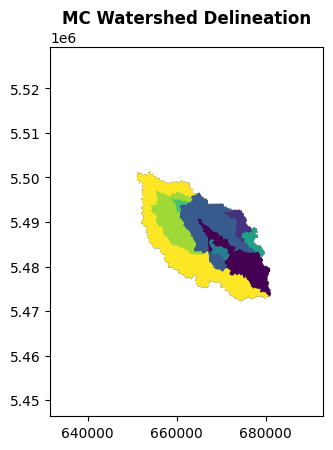

<Axes: title={'center': 'MC Watershed Delineation'}>

In [15]:


# Visualize Manning Canal watershed raster
data_name = DATA_RAW + "DEMs/mc_watershed_90000.tif"
tiff = rasterio.open(data_name)
rasterio.plot.show(tiff, title = "MC Watershed Delineation")

In [16]:
# Convert raster watershed output to vector polygons
wbt.raster_to_vector_polygons(
    i = 'mc_watershed_90000.tif', 
    output = 'mc_watershed_90000.shp'
)

.\whitebox_tools.exe --run="RasterToVectorPolygons" --wd="c:\Users\tsaleh\Documents\GIS-Projects\PWA\Data\Raw\manning\DEMs" --input='mc_watershed_90000.tif' --output='mc_watershed_90000.shp' -v --compress_rasters=False

*************************************
* Welcome to RasterToVectorPolygons *
* Powered by WhiteboxTools          *
* www.whiteboxgeo.com               *
*************************************
Reading data...
Clumping polygons: 0%
Clumping polygons: 1%
Clumping polygons: 2%
Clumping polygons: 3%
Clumping polygons: 4%
Clumping polygons: 5%
Clumping polygons: 6%
Clumping polygons: 7%
Clumping polygons: 8%
Clumping polygons: 9%
Clumping polygons: 10%
Clumping polygons: 11%
Clumping polygons: 12%
Clumping polygons: 13%
Clumping polygons: 14%
Clumping polygons: 15%
Clumping polygons: 16%
Clumping polygons: 17%
Clumping polygons: 18%
Clumping polygons: 19%
Clumping polygons: 20%
Clumping polygons: 21%
Clumping polygons: 22%
Clumping polygons: 23%
Clumping polygons: 24%
Clumping 

0

## Create BasinMaker Outlet Points

c:\Users\emilito\AppData\Local\anaconda3\envs\gpd_tutorial\lib\site-packages\IPython\core\interactiveshell.py:3448: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


(-97.00341666732322, -96.46991666698455, 49.35170832966098, 49.70829166312099)

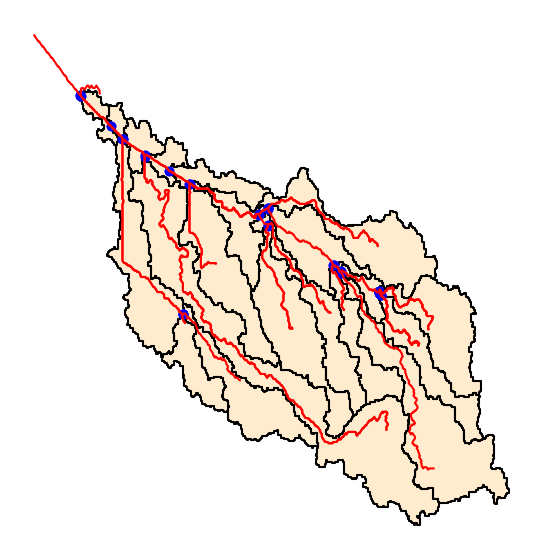

In [463]:
# Read in basinmaker subbasin and rivers shapefiles as geodataframes
#os.getcwd()
#os.chdir('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs')

bm_poly = gpd.read_file(DATA_PROCESSED + "Subbasins/mc_clrh_subbasins.shp")
#bm_rivers = gpd.read_file('basinmaker_rivers_MC.shp')
bm_rivers = gpd.read_file(DATA_RAW + "CLRH_RoutingProduct/05OE006/finalcat_info_v1-0_Project.shp")
#wbt_poly = gpd.read_file('mc_watershed.shp')

# Explode basinmaker geodataframe to split multipolygons into separate polygons
bm_poly_exploded = bm_poly.explode(ignore_index=True)

# Create new dataframe of points where basinmaker rivers intersect with basinmaker subbasins
points_df = gpd.GeoDataFrame(columns=['geometry'])

for i, row in bm_rivers.iterrows():
        for x, row in bm_poly_exploded.iterrows():
            poly_coords = bm_poly_exploded.geometry[x]
            line_coords = bm_rivers.geometry[i]
            polin = LineString(list(poly_coords.exterior.coords))
            #intersection
            pt = polin.intersection(line_coords)
            #print(pt.wkt)
            if pt.wkt != 'LINESTRING EMPTY':
                gdf_to_append = gpd.GeoDataFrame({'geometry': pt.wkt, 'SubId': bm_poly_exploded.SubId[x]}, index=[0])
                points_df = pd.concat([points_df, gdf_to_append], ignore_index=True)
#print(points_df)

# Convert points dataframe to geodataframe
geometry = points_df['geometry'].map(shapely.wkt.loads)
points_df = points_df.drop('geometry', axis=1)
points_gdf = gpd.GeoDataFrame(points_df, crs="EPSG:4326", geometry=geometry)
#points_gdf = points_gdf.set_crs(epsg=26914, allow_override=True)

# Explode points geodataframe to split multipoints into separate points
points_gdf_exploded = points_gdf.explode(ignore_index=True)

# Extract basinmaker rivers that intersect with basinmaker subbasins
bm_rivers_intersect = gpd.sjoin(bm_rivers, bm_poly_exploded, op='intersects')

# Plot basinmaker subbasins, rivers, and outlet points
f, ax = plt.subplots(1,1,figsize=(7,7))
bm_poly_exploded.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
points_gdf.plot(ax=ax, color = 'blue', edgecolor = 'blue')
bm_rivers_intersect.plot(ax=ax, color = 'red', edgecolor = 'red', linewidth = 1.5)
ax.axis('off')


In [18]:
# Write exploded basinmaker geodataframes to shapefiles
bm_poly_exploded.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_poly_exploded.shp")
points_gdf_exploded.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_pp.shp")

NameError: name 'bm_poly_exploded' is not defined

## Extract most downstream BasinMaker pourpoint per subbasin

In [19]:
# Read in observation points shapefile
obs_points = gpd.read_file('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs\\mc_pp_extract_proj.shp')

# Extract subbasins that contain observation points
bm_extract_basins = gpd.sjoin(bm_poly_exploded, obs_points, predicate='contains').drop_duplicates(subset=['SubId'], keep='first')

# Read in basinmaker pourpoints shapefile
pp = gpd.read_file('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs\\bm_pp.shp')

# Project basinmaker pourpoints to EPSG:26914 for processing with dem
pp_project = pp.to_crs(26914)

# Filter out subbasins that do not contain observation points
mask = pp_project['SubId'].isin(bm_extract_basins['SubId'])
pp_project_select_basins = pp_project[mask]

# Add column to pourpoints geodataframe with elevation values
import rasterio
# Create empty column for elevation values
pp_project_select_basins['Elevation'] = 0
# Extract elevation values for each point from dem
for index, row in pp_project_select_basins.iterrows():
    latitude = row['geometry'].y
    longitude = row['geometry'].x
    # Read the dem using rasterio library
    dem = rasterio.open('c:\\Users\\emilito\\Documents\\PWA\\Data\\Raw\\manning\\DEMs\\sr_dem_cgvd28_Resamp_1.tif')
    row, colmn = dem.index(longitude,latitude)
    dem_data = dem.read(1)
    # Add elevation values to geodataframe
    pp_project_select_basins['Elevation'].loc[index] = dem_data[row, colmn]

# Reproject pourpoints back to EPSG:4326
pp_reproject = pp_project_select_basins.to_crs(4326)

# Create geodataframe containing pourpoints with the lowest elevation value per subbasin
dstrm_pt_gdf =gpd.GeoDataFrame(columns=['geometry', 'SubId', 'Elevation'])

for i, row in pp_reproject.iterrows():
    df = pp_reproject.loc[[pp_reproject.loc[pp_reproject.SubId == pp_reproject.SubId[i], 'Elevation'].idxmin()]]
    dstrm_pt_gdf = pd.concat([dstrm_pt_gdf, df], ignore_index=True)

# Remove duplicate subbasin rows
dstrm_pt_no_dups = dstrm_pt_gdf.drop_duplicates(subset=['SubId'], keep='first', ignore_index=True)

# Plot basinmaker subbasins with outlet points
f, ax = plt.subplots(1,1,figsize=(7,7))
bm_poly_exploded.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
dstrm_pt_no_dups.plot(ax=ax, color = 'blue', edgecolor = 'blue')
ax.axis('off')

DataSourceError: c:\Users\emilito\Documents\PWA\Data\Raw\manning\DEMs\mc_pp_extract_proj.shp: No such file or directory

In [ ]:
# Write basinmaker outlet points to shapefile
dstrm_pt_no_dups.to_file("/Users/emilito/Documents/PWA/Data/Raw/manning/DEMs/bm_dstrm_pp.shp")